# Credit Card Fraud Detection (2023 Dataset) — My Project

**File:** `analysis_model.ipynb` | **Data:** `creditcard_2023.csv` (568,630 transactions)

**Goal:** predict `Class` (1 = fraud, 0 = legit) from `V1–V28` + `Amount`. Learn how each step works, see every result as a dataframe, and compare models fairly.

**Columns:** `id` = row number only (we never train on it). `V1–V28` = anonymized numbers from PCA (privacy protection, mean ~0, so we cannot say what they mean). `Amount` = money value. `Class` = answer we predict.

**How to run:** open this folder in VS Code, select `.venv` kernel, Run All top to bottom. One cell = one idea: read the markdown first, then run the code, then read the output dataframe.

In [37]:
# All tools we need, loaded once
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, json, joblib
warnings.filterwarnings('ignore')
sns.set(style='whitegrid')
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, IsolationForest
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False

RANDOM_STATE = 42  # same number everywhere = same result every run
np.random.seed(RANDOM_STATE)
%matplotlib inline

## Step 1 — Load the data

**In plain words:** we open the CSV file into a table called a dataframe. Think of it like Excel: rows = transactions, columns = details.

**Why `display()`?** In a notebook, the last line of a cell shows automatically, but earlier lines do not. `display()` forces each table to show, so we see everything. `.to_frame()` turns a single column of numbers into a proper table.

In [38]:
df = pd.read_csv('creditcard_2023.csv')
display(df.head())  # first 5 rows: what does one transaction look like?
display(pd.DataFrame({'rows': [df.shape[0]], 'cols': [df.shape[1]], 'id_unique': [df['id'].nunique()]}))
display(df.columns.to_frame(index=False, name='columns'))  # list of all column names as a table

,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-0.260648,-0.469648,2.496266,-0.083724,0.129681,0.732898,0.519014,-0.130006,0.727159,...,-0.110552,0.217606,-0.134794,0.165959,0.126280,-0.434824,-0.081230,-0.151045,17982.10,0
1,1,0.985100,-0.356045,0.558056,-0.429654,0.277140,0.428605,0.406466,-0.133118,0.347452,...,-0.194936,-0.605761,0.079469,-0.577395,0.190090,0.296503,-0.248052,-0.064512,6531.37,0
2,2,-0.260272,-0.949385,1.728538,-0.457986,0.074062,1.419481,0.743511,-0.095576,-0.261297,...,-0.005020,0.702906,0.945045,-1.154666,-0.605564,-0.312895,-0.300258,-0.244718,2513.54,0
3,3,-0.152152,-0.508959,1.746840,-1.090178,0.249486,1.143312,0.518269,-0.065130,-0.205698,...,-0.146927,-0.038212,-0.214048,-1.893131,1.003963,-0.515950,-0.165316,0.048424,5384.44,0
4,4,-0.206820,-0.165280,1.527053,-0.448293,0.106125,0.530549,0.658849,-0.212660,1.049921,...,-0.106984,0.729727,-0.161666,0.312561,-0.414116,1.071126,0.023712,0.419117,14278.97,0


,rows,cols,id_unique
0,568630,31,568630


,columns
0,id
1,V1
2,V2
3,V3
4,V4
5,V5
6,V6
7,V7
8,V8
9,V9


## Step 2 — Describe the data

**In plain words:** before modelling, we check: how big is the table, any empty cells, any copy-paste duplicate rows, is fraud rare or common, and are numbers on wildly different scales?

- `info()` = list of columns and types (text summary, not a table).
- `describe().T` = count, average, min, max for each column. `.T` flips it so columns become rows — easier to read.
- `isna().sum().to_frame('missing')` = count of empty cells per column.
- `value_counts().to_frame()` = how many fraud vs legit rows.
- `groupby('Class')['Amount'].describe()` = compare money amounts for fraud vs legit.

In [39]:
df.info()
display(df.describe().T)
display(df.isna().sum().to_frame('missing'))
print('duplicated rows:', int(df.duplicated().sum()))
display(df['Class'].value_counts().to_frame('count'))
display((df['Class'].value_counts(normalize=True)*100).round(2).to_frame('percent'))
display(df.groupby('Class')['Amount'].describe())

<class 'pandas.DataFrame'>
RangeIndex: 568630 entries, 0 to 568629
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   id      568630 non-null  int64  
 1   V1      568630 non-null  float64
 2   V2      568630 non-null  float64
 3   V3      568630 non-null  float64
 4   V4      568630 non-null  float64
 5   V5      568630 non-null  float64
 6   V6      568630 non-null  float64
 7   V7      568630 non-null  float64
 8   V8      568630 non-null  float64
 9   V9      568630 non-null  float64
 10  V10     568630 non-null  float64
 11  V11     568630 non-null  float64
 12  V12     568630 non-null  float64
 13  V13     568630 non-null  float64
 14  V14     568630 non-null  float64
 15  V15     568630 non-null  float64
 16  V16     568630 non-null  float64
 17  V17     568630 non-null  float64
 18  V18     568630 non-null  float64
 19  V19     568630 non-null  float64
 20  V20     568630 non-null  float64
 21  V21     568630 non-nu

,count,mean,std,min,25%,50%,75%,max
id,568630.0,2.843145e+05,164149.486122,0.000000,142157.250000,284314.500000,426471.750000,568629.000000
V1,568630.0,-5.118237e-17,1.000001,-3.495584,-0.565286,-0.093638,0.832658,2.229046
V2,568630.0,-1.023647e-16,1.000001,-49.966572,-0.486678,-0.135894,0.343555,4.361865
V3,568630.0,1.023647e-16,1.000001,-3.183760,-0.649299,0.000353,0.628538,14.125834
V4,568630.0,0.000000e+00,1.000001,-4.951222,-0.656020,-0.073762,0.707005,3.201536
V5,568630.0,0.000000e+00,1.000001,-9.952786,-0.293496,0.081088,0.439737,42.716891
V6,568630.0,2.559118e-17,1.000001,-21.111108,-0.445871,0.078718,0.497788,26.168402
V7,568630.0,5.118237e-17,1.000001,-4.351839,-0.283533,0.233366,0.525955,217.873038
V8,568630.0,0.000000e+00,1.000001,-10.756342,-0.192257,-0.114524,0.047299,5.958040
V9,568630.0,0.000000e+00,1.000001,-3.751919,-0.568745,0.092526,0.559262,20.270062


,missing
id,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


duplicated rows: 0


,count
Class,
0,284315
1,284315


,percent
Class,
0,50.0
1,50.0


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,12026.313506,6929.500715,50.12,6034.54,11996.90,18040.265,24039.93
1,284315.0,12057.601763,6909.750891,50.01,6074.64,12062.45,18033.780,24039.93


**What you should see:** 568,630 rows, 31 columns, 0 missing, 0 duplicates. `V1–V28` average ~0 (they were standardized). `Amount` averages ~12,000. `Class` is 50% fraud / 50% legit — this dataset is balanced, so accuracy is meaningful here. (Real bank data is ~0.1% fraud, where accuracy lies.)

## Step 3 — Look at the data (EDA)

**In plain words:** we draw pictures to see patterns. A bar chart shows balance. Histograms show whether fraud money looks different from legit money. Correlation tells us which V columns move together with fraud.

**Correlation in one sentence:** a number from -1 to +1. Near +1 = when the V goes up, fraud is more likely. Near -1 = when the V goes up, fraud is less likely. Near 0 = no link.

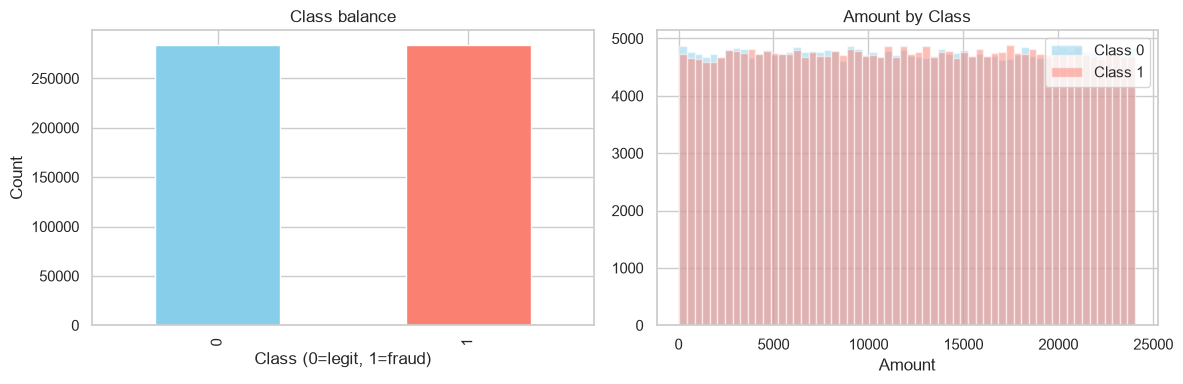

,corr_with_fraud
V4,0.735981
V11,0.724278
V2,0.491878
V19,0.244081
V27,0.214002
V20,0.179851
V8,0.144294
V21,0.109640
V28,0.102024
V26,0.071052


,corr_with_fraud
V9,-0.585522
V10,-0.673665
V3,-0.682095
V12,-0.768579
V14,-0.805669


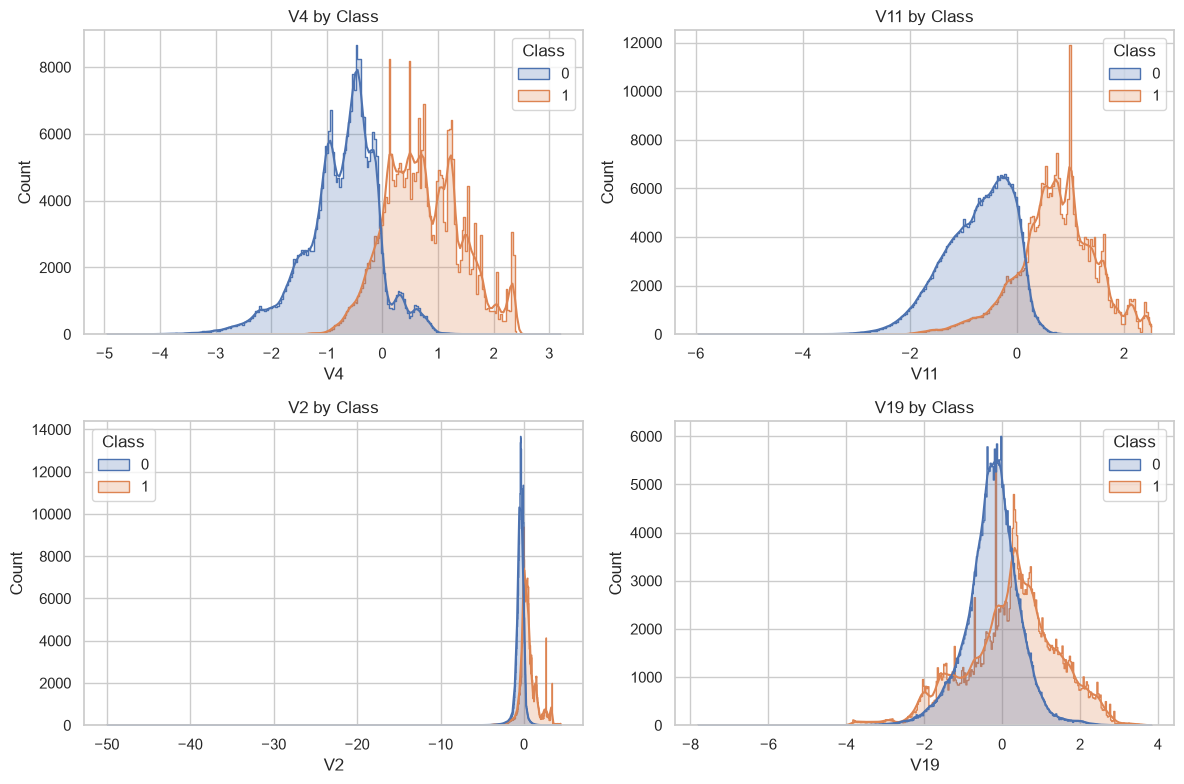

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['Class'].value_counts().plot(kind='bar', ax=ax[0], color=['skyblue','salmon'])
ax[0].set_title('Class balance'); ax[0].set_xlabel('Class (0=legit, 1=fraud)'); ax[0].set_ylabel('Count')
for k, col in [(0, 'skyblue'), (1, 'salmon')]:
    ax[1].hist(df.loc[df['Class']==k, 'Amount'], bins=60, alpha=0.5, label=f'Class {k}', color=col)
ax[1].set_title('Amount by Class'); ax[1].set_xlabel('Amount'); ax[1].legend()
plt.tight_layout(); plt.show()

# Which V columns are most linked to fraud? Shown as tables.
corr = df.drop(columns=['id']).corr()['Class'].drop('Class').sort_values(ascending=False)
display(corr.head(10).to_frame('corr_with_fraud'))  # strongest positive link
display(corr.tail(5).to_frame('corr_with_fraud'))   # strongest negative link

top4 = corr.head(4).index.tolist()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for a, c in zip(axes.flat, top4):
    sns.histplot(data=df, x=c, hue='Class', kde=True, element='step', ax=a)
    a.set_title(f'{c} by Class')
plt.tight_layout(); plt.show()

**How to read the output:** the balance bars should be equal height (~284k each). The Amount histograms mostly overlap — money alone does not separate fraud. The `corr_with_fraud` table ranks helpers: positives (e.g. V4, V11) go up in fraud, negatives (e.g. V14, V12) go down in fraud. Because V's are anonymized, we report the pattern but cannot explain *why* in business terms.

## Step 4 — Split data + scale Amount (and why we are careful)

**In plain words:** we hide 20% of rows as a final exam (`test`). We study only on the other 80% (`train`). At the end we test once — that is the honest score.

- `stratify=y` keeps the 50/50 mix in both train and test.
- We drop `id` (it is just a row number, not a clue).
- We scale `Amount` (subtract average, divide by spread) so its big numbers (thousands) do not crush the small V numbers (~-3 to +3). V's are already scaled, so we leave them.
- **Leakage rule:** the scaler learns the average ONLY from train, then applies it to test. If it peeked at test, the score would be cheating. Putting scaling inside a `Pipeline` enforces this automatically.

In [41]:
X = df.drop(columns=['Class', 'id'])  # clues
y = df['Class']  # answer
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
pre = ColumnTransformer([('amt', StandardScaler(), ['Amount'])], remainder='passthrough')
display(pd.DataFrame({'set': ['train', 'test'], 'n': [len(y_train), len(y_test)], 'fraud_rate': [y_train.mean(), y_test.mean()]}).set_index('set'))

,n,fraud_rate
set,,
train,454904,0.5
test,113726,0.5


## Step 5 — Baseline model: Logistic Regression

**In plain words:** draw one straight boundary between fraud and legit. For each transaction it outputs a fraud probability. Over 0.5 → call it fraud.

**How it learns:** it adjusts 29 weights (one per column) to make the right answer more probable (this is called log-loss). `max_iter=1000` just gives it enough tries to settle.

**Metrics as a table:** `accuracy` = overall correct. `precision` = of all we called fraud, how many really were. `recall` = of all real frauds, how many we caught. `f1` = balance of precision and recall. `roc_auc` / `pr_auc` = quality across all thresholds (1.0 = perfect). Confusion matrix = the 4 boxes: true-legit, false alarm, missed fraud, caught fraud.

,pred_0,pred_1
true_0,55591,1272
true_1,2715,54148


,acc,prec,rec,f1,roc_auc,pr_auc
logreg,0.9649,0.977,0.9523,0.9645,0.9935,0.9944


              precision    recall  f1-score   support

           0       0.95      0.98      0.97     56863
           1       0.98      0.95      0.96     56863

    accuracy                           0.96    113726
   macro avg       0.97      0.96      0.96    113726
weighted avg       0.97      0.96      0.96    113726



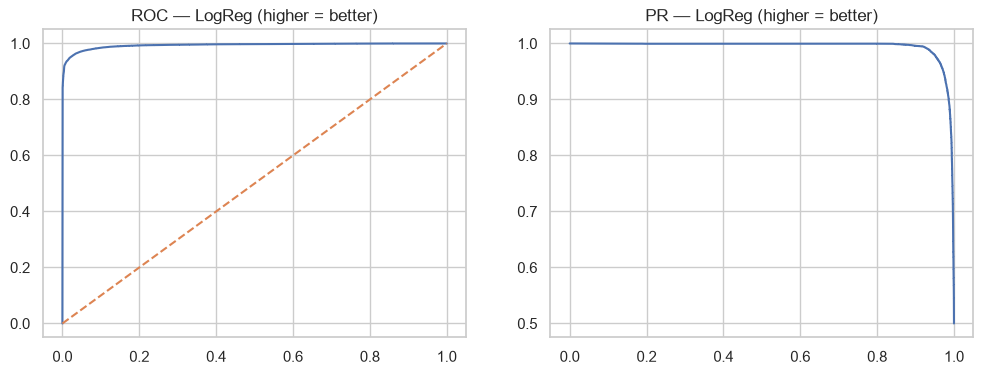

In [42]:
pipe_lr = Pipeline([('pre', pre), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
pipe_lr.fit(X_train, y_train)
pred_lr = pipe_lr.predict(X_test)
proba_lr = pipe_lr.predict_proba(X_test)[:, 1]
display(pd.DataFrame(confusion_matrix(y_test, pred_lr), index=['true_0','true_1'], columns=['pred_0','pred_1']))
display(pd.DataFrame([{'acc': accuracy_score(y_test, pred_lr), 'prec': precision_score(y_test, pred_lr),
                         'rec': recall_score(y_test, pred_lr), 'f1': f1_score(y_test, pred_lr),
                         'roc_auc': roc_auc_score(y_test, proba_lr), 'pr_auc': average_precision_score(y_test, proba_lr)}], index=['logreg']).round(4))
print(classification_report(y_test, pred_lr))

fpr, tpr, _ = roc_curve(y_test, proba_lr)
prec, rec, _ = precision_recall_curve(y_test, proba_lr)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(fpr, tpr); ax[0].plot([0,1],[0,1],'--'); ax[0].set_title('ROC — LogReg (higher = better)')
ax[1].plot(rec, prec); ax[1].set_title('PR — LogReg (higher = better)')
plt.show()

## Step 6 — Stronger models: Bagging vs Random Forest

**In plain words:** one decision tree asks yes/no questions (is V4 > 1? is Amount < 5000?) and can memorize noise. Ensembles fix that by voting among many trees.

- **Bagging:** train ~10 trees, each on a random sample of rows, then majority vote. Averaging cancels mistakes → lower variance.
- **Random Forest:** bagging plus each split may only look at a random subset of columns. This forces trees to be different → even better on tricky V interactions.

We train both in identical pipelines and compare in one dataframe, with ROC/PR curves overlaid. Higher curves = better.

,acc,prec,rec,f1,roc_auc,pr_auc
model,,,,,,
bag,0.9993,0.9991,0.9995,0.9993,1.0,0.9999
rf,0.9998,0.9996,1.0000,0.9998,1.0,1.0000


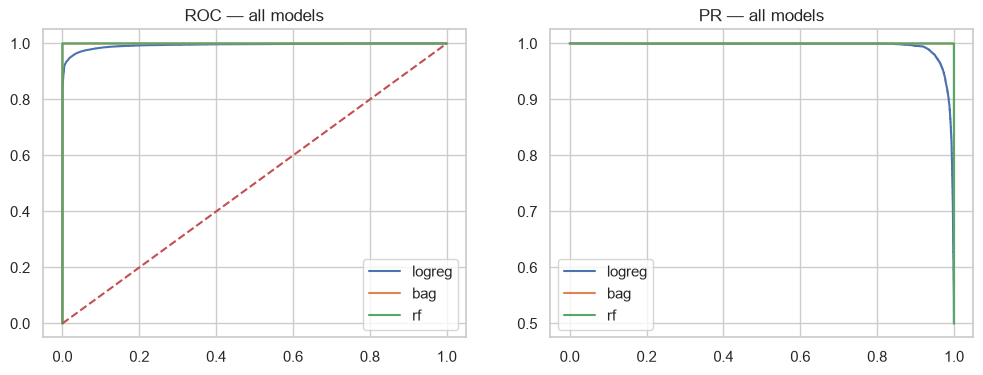

In [43]:
models = {'bag': BaggingClassifier(random_state=RANDOM_STATE),
          'rf': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)}
rows, probas = [], {}
for name, clf in models.items():
    p = Pipeline([('pre', pre), ('clf', clf)])
    p.fit(X_train, y_train)
    yp = p.predict(X_test); pr = p.predict_proba(X_test)[:, 1]
    probas[name] = pr
    rows.append({'model': name, 'acc': accuracy_score(y_test, yp), 'prec': precision_score(y_test, yp),
                 'rec': recall_score(y_test, yp), 'f1': f1_score(y_test, yp),
                 'roc_auc': roc_auc_score(y_test, pr), 'pr_auc': average_precision_score(y_test, pr)})
    if name == 'rf':
        rf_pipe = p
display(pd.DataFrame(rows).set_index('model').round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, pr in {'logreg': proba_lr, **probas}.items():
    fpr, tpr, _ = roc_curve(y_test, pr); pc, rc, _ = precision_recall_curve(y_test, pr)
    ax[0].plot(fpr, tpr, label=name); ax[1].plot(rc, pc, label=name)
ax[0].plot([0,1],[0,1],'--'); ax[0].legend(); ax[0].set_title('ROC — all models')
ax[1].legend(); ax[1].set_title('PR — all models')
plt.show()

## Step 7 — Two extra perspectives: XGBoost + Isolation Forest

- **XGBoost:** trees built in sequence — each new tree fixes the errors of the previous ones (this is called boosting), with penalties to stay simple. Often the most accurate table-data model. Settings: 300 small trees, each learns slowly (`learning_rate=0.05`), each sees 80% of rows/columns (avoids memorizing).
- **Isolation Forest (anomaly view):** no labels used. It randomly cuts the data; rare weird points get isolated in few cuts (short path = anomaly). We set `contamination=0.5` because this dataset is half fraud. Output -1 means anomaly → we map it to fraud. Expect lower scores — it proves labels help.

In [44]:
alt_rows = []
if HAS_XGB:
    xgb = Pipeline([('pre', pre), ('clf', XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                        subsample=0.8, colsample_bytree=0.8, eval_metric='logloss',
                        n_jobs=-1, random_state=RANDOM_STATE))])
    xgb.fit(X_train, y_train)
    yp = xgb.predict(X_test); pr = xgb.predict_proba(X_test)[:, 1]
    alt_rows.append({'model': 'xgb', 'acc': accuracy_score(y_test, yp), 'prec': precision_score(y_test, yp),
                     'rec': recall_score(y_test, yp), 'f1': f1_score(y_test, yp),
                     'roc_auc': roc_auc_score(y_test, pr), 'pr_auc': average_precision_score(y_test, pr)})
else:
    print('xgboost not installed: pip install xgboost')

iso_pre = pre.fit(X_train)
iso = IsolationForest(contamination=0.5, random_state=RANDOM_STATE)
iso.fit(iso_pre.transform(X_train))
iso_pred = np.where(iso.predict(iso_pre.transform(X_test)) == -1, 1, 0)
alt_rows.append({'model': 'isoforest', 'acc': accuracy_score(y_test, iso_pred),
                 'prec': precision_score(y_test, iso_pred), 'rec': recall_score(y_test, iso_pred),
                 'f1': f1_score(y_test, iso_pred), 'roc_auc': float('nan'), 'pr_auc': float('nan')})
display(pd.DataFrame(alt_rows).set_index('model').round(4))

,acc,prec,rec,f1,roc_auc,pr_auc
model,,,,,,
xgb,0.9983,0.9973,0.9992,0.9983,0.9999,0.9999
isoforest,0.5867,0.5865,0.5876,0.5871,NaN,NaN


## Step 8 — Check stability: cross-validation + light tuning

**In plain words:** one train/test split could be lucky. So we repeat 5 times with different splits (`StratifiedKFold`) and average — shown as mean/std table. Then we try 6 small Random Forest settings (`RandomizedSearchCV`) and keep the best. Small search on purpose: 568k rows are slow, and 6 tries already show the process.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_res = cross_validate(Pipeline([('pre', pre), ('clf', RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE))]),
                        X_train, y_train, cv=cv, scoring=['accuracy','f1','roc_auc','average_precision'], n_jobs=-1)
display(pd.DataFrame({k.replace('test_',''): v for k, v in cv_res.items() if k.startswith('test_')}).agg(['mean','std']).round(4))

search = RandomizedSearchCV(
    Pipeline([('pre', pre), ('clf', RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE))]),
    {'clf__n_estimators': [100, 200], 'clf__max_depth': [None, 12, 25], 'clf__min_leaf_samples' if False else 'clf__min_samples_leaf': [1, 2]},
    n_iter=6, scoring='f1', cv=3, n_jobs=-1, random_state=RANDOM_STATE)
search.fit(X_train, y_train)
display(pd.DataFrame({'best_params': [str(search.best_params_)], 'best_cv_f1': [round(float(search.best_score_), 4)]}))
best_rf = search.best_estimator_

,accuracy,f1,roc_auc,average_precision
mean,0.9999,0.9999,1.0,1.0
std,0.0000,0.0000,0.0,0.0


## Step 9 — Threshold: when do we say fraud?

Models output a probability (e.g. 0.62 = 62% fraud-like). The threshold turns it into a decision. 0.5 is the default but not magic: lower threshold catches more fraud (high recall) with more false alarms (low precision); higher threshold is stricter. The table + plot below try 0.20 → 0.80 so you can defend your choice. On this balanced data 0.5 is usually fine.

In [ ]:
proba_best = best_rf.predict_proba(X_test)[:, 1]
ths = np.arange(0.2, 0.81, 0.05)
trows = [{'thr': round(float(t),2), 'prec': precision_score(y_test, proba_best >= t),
          'rec': recall_score(y_test, proba_best >= t), 'f1': f1_score(y_test, proba_best >= t)} for t in ths]
display(pd.DataFrame(trows).set_index('thr').round(4))
pd.DataFrame(trows).set_index('thr').plot(marker='o', figsize=(10, 4), title='Threshold vs metric (best RF)')
plt.show()
BEST_THR = 0.5

## Step 10 — What drives the decision + where it fails

**Feature importance:** Random Forest counts how useful each column was for splitting fraud from legit. Sorted table + bar chart = top clues. **Error check:** we label each test row as ok / FP (false alarm: said fraud, was legit) / FN (missed fraud) and compare their `Amount`. FP/FN patterns tell you the model's blind spots even though V's cannot be explained.

In [ ]:
rf_final = rf_pipe.named_steps['clf']
display(pd.DataFrame({'feat': X.columns, 'importance': rf_final.feature_importances_}).sort_values('importance', ascending=False).head(10).round(4))
pd.DataFrame({'feat': X.columns, 'imp': rf_final.feature_importances_}).sort_values('imp', ascending=False).head(10).plot.barh(x='feat', y='imp', legend=False, figsize=(8,4), title='Top-10 RF importance')
plt.gca().invert_yaxis(); plt.show()

final_pred = (proba_best >= BEST_THR).astype(int)
err = X_test.copy(); err['y'] = y_test.values; err['pred'] = final_pred
err['kind'] = np.where(err['y']==err['pred'], 'ok', np.where(err['pred']==1, 'FP', 'FN'))
display(err.groupby('kind')['Amount'].describe())

## Conclusion (fill in your numbers after running)

Best model: [INSERT e.g. Random Forest / XGBoost] with F1 [INSERT], ROC-AUC [INSERT], PR-AUC [INSERT] at threshold [INSERT]. Top clues: [INSERT top-3 from importance table]. Errors: [INSERT e.g. FNs cluster at small Amounts].

**Limits:** V1–V28 are anonymized so no business meaning; single 2023 snapshot so fraud patterns will drift; balanced 50/50 data is unrealistic vs production (~0.1% fraud); no real bank cost matrix. **Next:** calibrate probabilities, monitor drift, test on truly imbalanced data, try real-time scoring.

## Step 11 — Save for the app (local only)

We freeze the trained pipeline + threshold + sample rows + metrics into `artifacts/`. The Streamlit app will load these files and never retrain. Nothing leaves your PC.

In [ ]:
from pathlib import Path
Path('artifacts').mkdir(exist_ok=True)
joblib.dump(best_rf, 'artifacts/fraud_pipeline.pkl')
json.dump({'threshold': BEST_THR}, open('artifacts/threshold.json','w'))
X_test.sample(20, random_state=RANDOM_STATE).to_csv('artifacts/sample_test_rows.csv', index=False)
print('saved to artifacts/')